# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier # por defecto este hace soft vouting, pilla los porcentajes de votaciones y predice
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import accuracy_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from xgboost import XGBClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import GradientBoostingClassifier
import xgboost
from sklearn.metrics import accuracy_score, classification_report

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [11]:
from scipy.io import loadmat

mat = loadmat("data/ejer_1_data1.mat")



In [12]:
mat.keys()

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])

#### 3. Create a DataFrame with the features and target

In [13]:
df = pd.DataFrame(mat["X"], columns=["x1", "x2"])
df["y"] = mat["y"].ravel()

print(df.head())
print(df.info())

       x1      x2  y
0  1.9643  4.5957  1
1  2.2753  3.8589  1
2  2.9781  4.5651  1
3  2.9320  3.5519  1
4  3.5772  2.8560  1
<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      51 non-null     float64
 1   x2      51 non-null     float64
 2   y       51 non-null     uint8  
dtypes: float64(2), uint8(1)
memory usage: 999.0 bytes
None


#### 4. Plot a scatterplot with the data

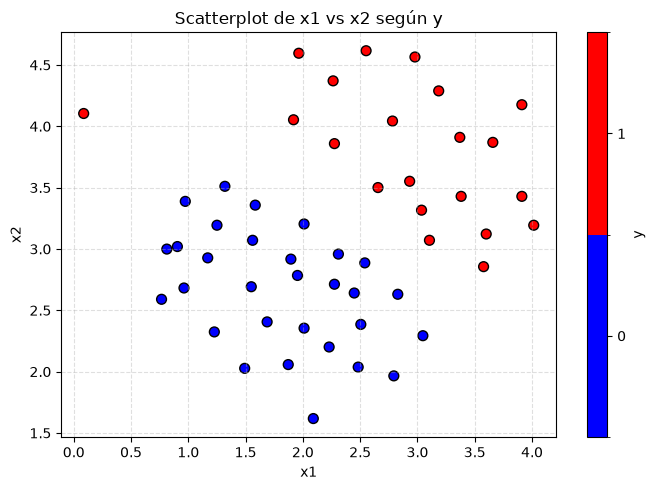

In [14]:
from matplotlib.colors import BoundaryNorm, ListedColormap
import matplotlib.pyplot as plt

cmap = ListedColormap(["blue", "red"])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

plt.figure(figsize=(7, 5))
plt.scatter(df["x1"], df["x2"], c=df["y"], cmap=cmap, norm=norm, edgecolor="k", s=50)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Scatterplot de x1 vs x2 según y")
plt.colorbar(ticks=[0, 1], label="y")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [15]:
from sklearn.svm import LinearSVC

clf = LinearSVC(C=1, loss="hinge", max_iter=10000)
clf.fit(df[["x1", "x2"]], df["y"])

,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'hinge'
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",10000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0


#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [16]:
score = clf.score(df[["x1", "x2"]], df["y"])
print(f"Accuracy con C=1: {score:.4f}")

Accuracy con C=1: 0.9804


It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [17]:
from sklearn.svm import LinearSVC

X = df[["x1", "x2"]]
y = df["y"]

for c in [1, 10, 50, 100, 500, 1000, 5000]:
  clf_c = LinearSVC(C=c, loss="hinge", max_iter=100000)
  clf_c.fit(X, y)
  acc = clf_c.score(X, y)
  print(f"C={c:<5} -> Accuracy: {acc:.4f}")
  if acc == 1.0:
    mejor_c = c
    mejor_clf = clf_c
    break

C=1     -> Accuracy: 0.9804
C=10    -> Accuracy: 0.9804
C=50    -> Accuracy: 0.9804
C=100   -> Accuracy: 0.9804
C=500   -> Accuracy: 1.0000


c:\Users\haize\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

c:\Users\haize\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


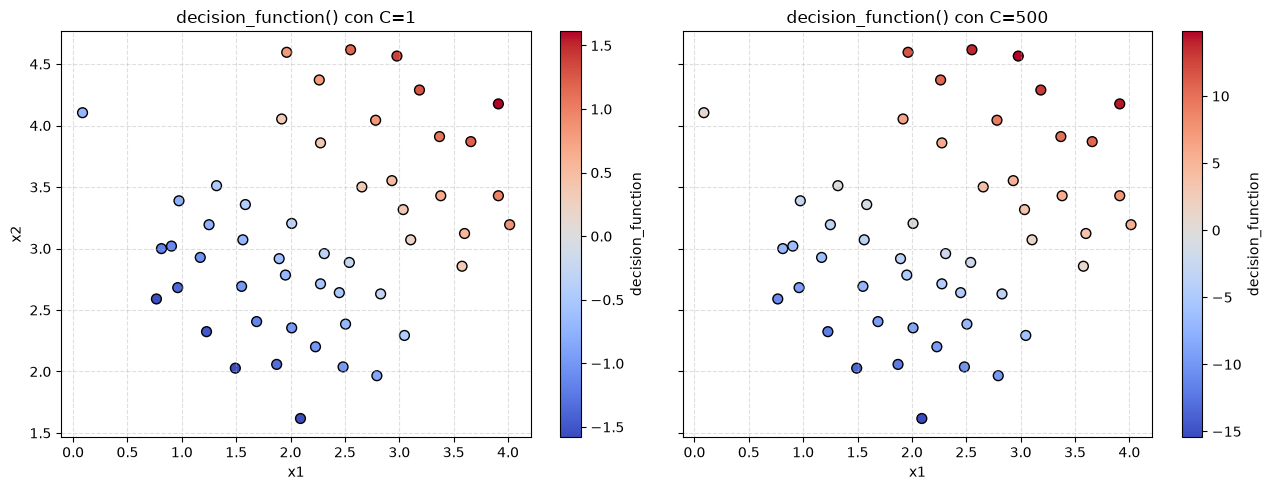

In [21]:
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC

X = df[["x1", "x2"]]
y = df["y"]

# Modelo con C=1000 (asumiendo que `clf` con C=1 ya está entrenado)
clf_1000 = LinearSVC(C=500, loss="hinge", max_iter=100000)
clf_1000.fit(X, y)

scores_1 = clf.decision_function(X)
scores_1000 = clf_1000.decision_function(X)

# Gráficos en paralelo
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

sc1 = axes[0].scatter(
    X["x1"], X["x2"], c=scores_1, cmap="coolwarm", edgecolor="k", s=50
)
axes[0].set_title("decision_function() con C=1")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].grid(True, linestyle="--", alpha=0.4)
fig.colorbar(sc1, ax=axes[0], label="decision_function")

sc2 = axes[1].scatter(
    X["x1"], X["x2"], c=scores_1000, cmap="coolwarm", edgecolor="k", s=50
)
axes[1].set_title("decision_function() con C=500")
axes[1].set_xlabel("x1")
axes[1].grid(True, linestyle="--", alpha=0.4)
fig.colorbar(sc2, ax=axes[1], label="decision_function")

plt.tight_layout()
plt.show()

#### 9. Do the same with the second model

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

#### 1. Load the data `ejer_1_data2.mat`

In [20]:

mat2 = loadmat("data/ejer_1_data2.mat")
mat2

{'__header__': b'MATLAB 5.0 MAT-file, Platform: GLNXA64, Created on: Sun Nov 13 14:28:54 2011',
 '__version__': '1.0',
 '__globals__': [],
 'X': array([[0.107143 , 0.60307  ],
        [0.093318 , 0.649854 ],
        [0.0979263, 0.705409 ],
        ...,
        [0.975806 , 0.439474 ],
        [0.989631 , 0.425439 ],
        [0.996544 , 0.414912 ]], shape=(863, 2)),
 'y': array([[1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
        [1],
    

#### 2. Create a DataFrame with the features and target

In [27]:
df2 = pd.DataFrame(mat2["X"], columns=["x1", "x2"])
df2["y"] = mat2["y"].ravel()

print(df2.head())
print(df2.info())

         x1        x2  y
0  0.107143  0.603070  1
1  0.093318  0.649854  1
2  0.097926  0.705409  1
3  0.155530  0.784357  1
4  0.210829  0.866228  1
<class 'pandas.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      863 non-null    float64
 1   x2      863 non-null    float64
 2   y       863 non-null    uint8  
dtypes: float64(2), uint8(1)
memory usage: 14.5 KB
None


#### 3. Plot a scatterplot with the data

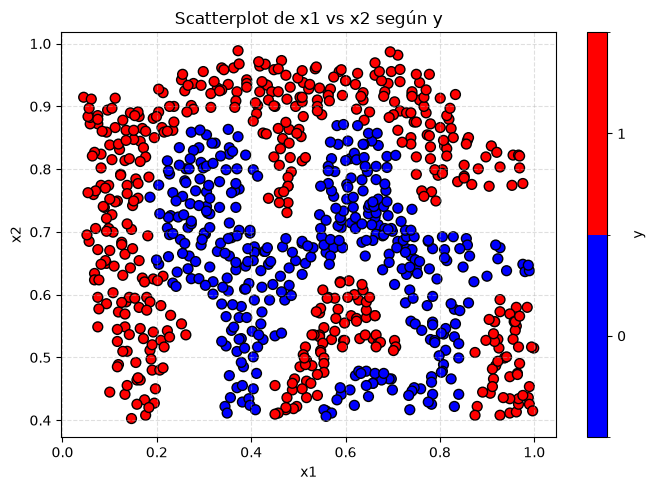

In [28]:
from matplotlib.colors import BoundaryNorm, ListedColormap
import matplotlib.pyplot as plt

cmap = ListedColormap(["blue", "red"])
norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

plt.figure(figsize=(7, 5))
plt.scatter(df2["x1"], df2["x2"], c=df2["y"], cmap=cmap, norm=norm, edgecolor="k", s=50)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Scatterplot de x1 vs x2 según y")
plt.colorbar(ticks=[0, 1], label="y")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [ ]:
from sklearn.svm import SVC

X2 = df2[["x1", "x2"]]
y2 = df2["y"]

svc = SVC(C=100, gamma=10, probability=True) #normalmente aquí se pone el kernel que puede ser 'poly', 'rbf' (ahora por defecto es rbf) o 'linear'

#### 5. Fit the classifier and get the score

In [31]:
svc.fit(X2, y2)
score2 = svc.score(X2, y2)
print(f"Accuracy con C=100, gamma=10: {score2:.4f}")

Accuracy con C=100, gamma=10: 0.9699


c:\Users\haize\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

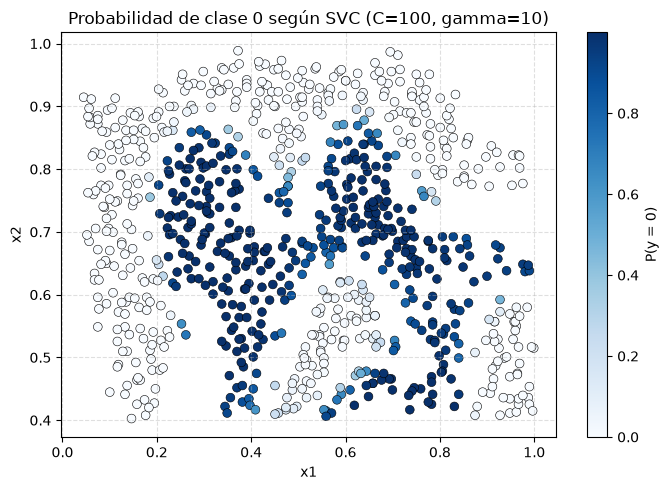

In [32]:
import matplotlib.pyplot as plt

# Índice de la clase 0 dentro de svc.classes_ (normalmente 0 si las clases son [0, 1])
idx_0 = list(svc.classes_).index(0)
prob_0 = svc.predict_proba(X2)[:, idx_0]

plt.figure(figsize=(7, 5))
sc = plt.scatter(
    X2["x1"], X2["x2"], c=prob_0, cmap="Blues", edgecolor="k", linewidth=0.4, s=40
)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Probabilidad de clase 0 según SVC (C=100, gamma=10)")
plt.colorbar(sc, label="P(y = 0)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()